# 02 — E1: retrieval methods (owner: H)

**Question.** Four back ends — exact PyTorch KNN (ours), exact FAISS Flat, FAISS IVF, and our
K-means index (bonus) — how do they trade Recall@10 against p95 latency and memory, and how does
the trade-off move as the corpus grows?

**What we ran.** The FiQA dev grid: 57,638 docs, 500 queries, k = 10, 384-d MiniLM embeddings
(7 configurations), plus a corpus-size sweep at 10k / 25k / 57,638 docs with nlist = 240 fixed.
Accuracy comes from `experiments/results/*/metrics.json`; latency uses the isolated-bench protocol
(natural threads, one process per backend — see wiki/experiments/e1_summary.md) so the numbers are
comparable with the report table.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().parent                     
sys.path.insert(0, str(REPO / "src"))
from finsight.report import BLUE, INK_2, ORANGE, apply_style, markdown_table, save_figure

apply_style()
RESULTS = REPO / "experiments" / "results"


def metrics(run_id):
    return json.loads((RESULTS / run_id / "metrics.json").read_text())


# 1. load the 7 grid runs
# 2. store them in a dict so later cells can look them up by run_id
GRID = {rid: metrics(rid) for rid in
        ["run_e1_001", "run_e1_002", "run_e1_003", "run_e1_004", "run_e1_005", "run_e1_006",
         "run_bonus_001"]}
[(rid, round(m["recall@10"], 4), round(m["latency_p95_ms"], 4)) for rid, m in GRID.items()]

[('run_e1_001', 0.4665, 0.7645),
 ('run_e1_002', 0.4665, 1.235),
 ('run_e1_003', 0.2831, 0.0153),
 ('run_e1_004', 0.3734, 0.0356),
 ('run_e1_005', 0.4383, 0.1065),
 ('run_e1_006', 0.4665, 0.3659),
 ('run_bonus_001', 0.4435, 1.9781)]

## 1. The accuracy–latency Pareto plot

Every point is one configuration. Exact search sits top-left (slowest, perfect recall); IVF moves
right along the speed axis as `nprobe` shrinks. The interesting region is the knee around
nprobe = 4–16.

The p95 values below are the natural-threads numbers (isolated-bench protocol) — the same ones the
report table uses. They are **not** read from the JSON, because `run_experiment.py` was run with
`OMP_NUM_THREADS=1`, which distorts them (faiss_flat shows 1.235 ms there vs 0.829 ms natural).

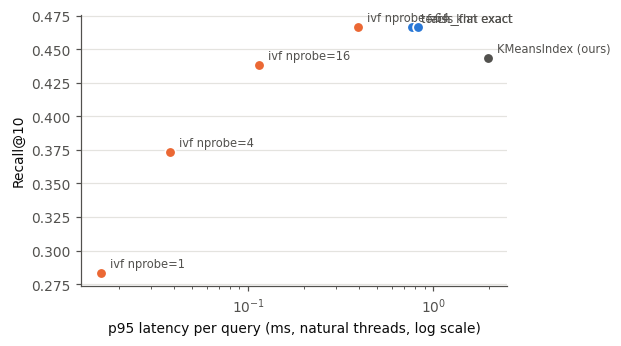

In [7]:
PARETO = [
    # (run_id, label, p95 natural threads, ms) — p95 from wiki/experiments/e1_summary.md
    ("run_e1_001", "torch_knn exact", 0.765),
    ("run_e1_002", "faiss_flat exact", 0.829),
    ("run_e1_003", "ivf nprobe=1", 0.016),
    ("run_e1_004", "ivf nprobe=4", 0.038),
    ("run_e1_005", "ivf nprobe=16", 0.114),
    ("run_e1_006", "ivf nprobe=64", 0.391),
    ("run_bonus_001", "KMeansIndex (ours)", 1.978),
]

fig, ax = plt.subplots(figsize=(5.0, 3.2))
for rid, label, p95 in PARETO:
    m = GRID[rid]
    color = BLUE if "exact" in label else (ORANGE if label.startswith("ivf") else INK_2)
    ax.plot(p95, m["recall@10"], "o", color=color, markeredgecolor="white",
            markeredgewidth=1.2, markersize=7, zorder=3)
    ax.annotate(label, (p95, m["recall@10"]), xytext=(6, 4), textcoords="offset points",
                color=INK_2, fontsize=7.5)
ax.set_xscale("log")
ax.set_xlabel("p95 latency per query (ms, natural threads, log scale)")
ax.set_ylabel("Recall@10")
save_figure(fig, "e1_pareto",
            "FiQA dev grid, 57,638 docs. Exact search trades speed; IVF's knee sits at nprobe 16, losing 2.82 points of Recall@10 for a 6.7x speed-up, while our K-means index matches"
            "IVF accuracy at 17x the cost.")
plt.show()

## 2. Memory and build time

Latency is only half of the efficiency story. Exact search has (almost) no build cost and stores
raw vectors; IVF pays a K-means build once and stores the same vectors plus centroids and the
inverted lists; our K-means index stores the same as IVF but builds in Python.

Note: `report/tables/e1_methods.tex` already holds the report-facing version of this table — this
cell only *prints* the Markdown, it must not overwrite that file.

In [3]:
rows = [{"Method": lab, "Recall@10": f"{GRID[rid]['recall@10']:.4f}",
         "Memory (MB)": f"{GRID[rid]['index_memory_mb']:.2f}",
         "Build (s)": f"{GRID[rid]['build_time_s']:.4f}"}
        for rid, lab in [("run_e1_001", "TorchKNN (exact)"), ("run_e1_002", "FAISS Flat (exact)"),
                          ("run_e1_005", "FAISS IVF 240/16"), ("run_bonus_001", "KMeansIndex (ours)")]]
print(markdown_table(rows))

| Method | Recall@10 | Memory (MB) | Build (s) |
|---|---|---|---|
| TorchKNN (exact) | 0.4665 | 84.43 | 0.0001 |
| FAISS Flat (exact) | 0.4665 | 84.43 | 0.0350 |
| FAISS IVF 240/16 | 0.4383 | 84.43 | 0.1829 |
| KMeansIndex (ours) | 0.4435 | 85.22 | 0.7650 |



## 3. Scaling: does the IVF speed-up grow with corpus size?

This is the question behind config B: if IVF only pays off at huge N, the dev result would not
transfer. We re-ran the *same* configuration (nlist = 240, nprobe = 16) on 10k and 25k docs (all
relevant docs kept, rest sampled, seed 42) and compare against the 57,638-doc grid runs. Latency
protocol here is `OMP_NUM_THREADS=1`, consistent across all three sizes.

Expected shape (from wiki/experiments/e1_scale.md): speed-up grows 3.4× → 6.5× → 7.2×, sub-linearly,
bounded by the 240/16 ≈ 15× probe-ratio ratio; IVF's accuracy loss stays ≈ −2.5–2.8 pt at every N.

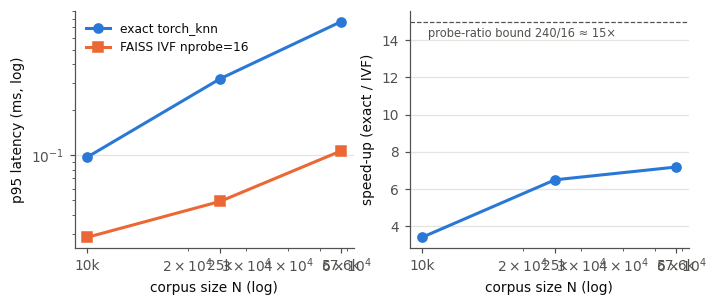

N= 10000  torch R@10 0.6295  ivf R@10 0.6012  Δ -2.83 pt
N= 25000  torch R@10 0.5372  ivf R@10 0.5124  Δ -2.49 pt
N= 57638  torch R@10 0.4665  ivf R@10 0.4383  Δ -2.82 pt


In [8]:
Ns = [10_000, 25_000, 57_638]
torch_by_n = {10_000: metrics("run_e1s_001"), 25_000: metrics("run_e1s_003"), 57_638: metrics("run_e1_001")}
ivf_by_n   = {10_000: metrics("run_e1s_002"), 25_000: metrics("run_e1s_004"), 57_638: metrics("run_e1_005")}

t_p95 = [torch_by_n[n]["latency_p95_ms"] for n in Ns]
i_p95 = [ivf_by_n[n]["latency_p95_ms"] for n in Ns]
speed = [t / i for t, i in zip(t_p95, i_p95)]
t_rec = [torch_by_n[n]["recall@10"] for n in Ns]
i_rec = [ivf_by_n[n]["recall@10"] for n in Ns]

fig, (a, b) = plt.subplots(1, 2, figsize=(7.2, 2.8))
a.plot(Ns, t_p95, "o-", color=BLUE, label="exact torch_knn")
a.plot(Ns, i_p95, "s-", color=ORANGE, label="FAISS IVF nprobe=16")
a.set_xscale("log"); a.set_yscale("log")
a.set_xticks(Ns, ["10k", "25k", "57.6k"])
a.set_xlabel("corpus size N (log)")
a.set_ylabel("p95 latency (ms, log)")
a.legend(fontsize=8)

b.plot(Ns, speed, "o-", color=BLUE)
b.axhline(240 / 16, ls="--", lw=0.8, color=INK_2)
b.annotate("probe-ratio bound 240/16 ≈ 15×", (Ns[0], 240 / 16), xytext=(4, -10),
           textcoords="offset points", color=INK_2, fontsize=7.5)
b.set_xscale("log")
b.set_xticks(Ns, ["10k", "25k", "57.6k"])
b.set_xlabel("corpus size N (log)")
b.set_ylabel("speed-up (exact / IVF)")
save_figure(fig, "e1_scaling",
             "Same IVF configuration on three corpus sizes. Speed-up over exact search grows 3.4x → 6.5x → 7.2× but stays below the 240/16 ≈ 15× probe-ratio bound"
             "IVF's accuracy loss holds at ~2.5–2.8 points regardless of N."
)
plt.show()

for n, tr, ir in zip(Ns, t_rec, i_rec):
    print(f"N={n:6d}  torch R@10 {tr:.4f}  ivf R@10 {ir:.4f}  Δ {(ir - tr) * 100:+.2f} pt")

## Findings


- Exact control: torch_knn and faiss_flat agree bit-for-bit on all metrics → a correctness control; flat adds nothing beyond a reference implementation.
- Knee: nprobe 1/4/16/64 lose 18.35 / 9.32 / 2.82 / 0.00 pt at 46.6× / 20.2× / 6.7× / 2.0× speed-up. nprobe=16 is the knee: 2.82 pt recall cost for 6.7× speed-up.
- Our KMeansIndex: +0.52 pt accuracy over IVF but ~17× slower (Python loop vs fused C++ scan), so it is not yet a viable replacement.
- Scaling: speed-up grows sub-linearly from 3.4× → 6.5× → 7.2× toward the 15× probe-ratio bound; IVF's recall loss is corpus-size-independent; R@10 falls with N because the subsample only adds distractors — a rise in task difficulty, not a degradation of the method.